# Prepare available ERCOT data (2021–2024)

This notebook replaces the missing intermediate spreadsheets with one
timestamp-safe canonical dataset. It reads the existing files in
`Data Download` and writes only under `Fixed Methods/fixed_data`.

The original `Data Download` and `Data Preparation` folders are read-only.


In [ ]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "Data Download").is_dir() and (candidate / "FCNN Direct Method").is_dir():
            return candidate
    raise FileNotFoundError(
        "Cannot locate the repository root containing Data Download and the method folders."
    )


PROJECT_ROOT = find_project_root()
RAW_DATA_DIR = PROJECT_ROOT / "Data Download"
FIXED_DATA_DIR = PROJECT_ROOT / "fixed_data"
FIXED_DATA_DIR.mkdir(parents=True, exist_ok=True)
YEARS = range(2021, 2025)

print("Project root:", PROJECT_ROOT)
print("Raw data directory:", RAW_DATA_DIR)
print("Fixed data directory:", FIXED_DATA_DIR)


In [2]:
def canonicalize_ercot_time(values):
    """Convert ERCOT local clock time to a unique, continuous UTC-naive key."""
    local_time = pd.to_datetime(values, errors="coerce")
    if local_time.isna().any():
        raise ValueError("ERCOT generation data contains invalid timestamps.")
    localized = local_time.dt.tz_localize(
        "America/Chicago", ambiguous="infer", nonexistent="raise"
    )
    return localized.dt.tz_convert("UTC").dt.tz_localize(None)


def validate_hourly(frame, label):
    if frame["time"].isna().any():
        raise ValueError(f"{label} contains invalid timestamps.")
    if frame["time"].duplicated().any():
        duplicates = frame.loc[frame["time"].duplicated(False), "time"].head().tolist()
        raise ValueError(f"{label} contains duplicate timestamps: {duplicates}")
    frame = frame.sort_values("time").reset_index(drop=True)
    bad = frame["time"].diff().iloc[1:].ne(pd.Timedelta(hours=1))
    if bad.any():
        positions = np.flatnonzero(bad.to_numpy())[:5] + 1
        examples = frame.iloc[positions]["time"].tolist()
        raise ValueError(f"{label} is not continuous hourly data near: {examples}")
    return frame


In [3]:
def read_generation(
    year, sheet_name, generation_column, capacity_column,
    output_generation, output_capacity, output_load,
):
    path = RAW_DATA_DIR / f"ERCOT_{year}_Hourly_WindSolar_Output.xlsx"
    if not path.is_file():
        raise FileNotFoundError(path)
    raw = pd.read_excel(path, sheet_name=sheet_name)
    time_column = "Time (Hour-Ending)" if "Time (Hour-Ending)" in raw.columns else "Time"
    return pd.DataFrame({
        "time": canonicalize_ercot_time(raw[time_column]),
        output_generation: pd.to_numeric(raw[generation_column], errors="coerce"),
        output_capacity: pd.to_numeric(raw[capacity_column], errors="coerce"),
        output_load: pd.to_numeric(raw["ERCOT.LOAD"], errors="coerce"),
    })


In [4]:
solar = pd.concat([
    read_generation(
        year, "Solar Data", "ERCOT.PVGR.GEN", "Total Solar Installed, MW",
        "solar_generation", "solar_installed", "solar_source_load",
    )
    for year in YEARS
], ignore_index=True)
wind = pd.concat([
    read_generation(
        year, "Wind Data", "ERCOT.WIND.GEN", "Total Wind Installed, MW",
        "wind_generation", "wind_installed", "total_load",
    )
    for year in YEARS
], ignore_index=True)

solar = validate_hourly(solar, "solar")
wind = validate_hourly(wind, "wind")
print("Rows before merge:", len(solar), len(wind))


Rows before merge: 35065 35065


In [5]:
data = (
    wind.merge(solar, on="time", how="inner", validate="one_to_one")
    .sort_values("time")
    .reset_index(drop=True)
)
if not (len(data) == len(solar) == len(wind)):
    raise ValueError(
        "Timestamp merge lost rows; solar and wind timelines are not identical."
    )
load_difference = np.abs(data["total_load"] - data["solar_source_load"])
if load_difference.max() > 1e-6:
    raise ValueError(
        "Wind and solar sheets disagree on ERCOT.LOAD; "
        f"maximum difference={load_difference.max()} MW."
    )
data = data.drop(columns="solar_source_load")
numeric_columns = [
    "total_load", "solar_generation", "solar_installed",
    "wind_generation", "wind_installed",
]
if data[numeric_columns].isna().any().any():
    raise ValueError("Canonical data contains missing numeric values.")
if (data[["solar_generation", "solar_installed", "wind_generation", "wind_installed"]] < 0).any().any():
    raise ValueError("Generation and installed capacity must be non-negative.")

data["net_load"] = (
    data["total_load"] - data["solar_generation"] - data["wind_generation"]
)
local_time = data["time"].dt.tz_localize("UTC").dt.tz_convert("America/Chicago")
hour = local_time.dt.hour.to_numpy(dtype=float)
data["clear_sky_proxy"] = np.maximum(
    np.sin(np.pi * (hour - 6.0) / 12.0), 0.0
)
data = validate_hourly(data, "canonical data")
print("Canonical shape:", data.shape)
print("Range:", data["time"].min(), "to", data["time"].max())
data.head()


Canonical shape: (35065, 8)
Range: 2021-01-01 06:00:00 to 2025-01-01 06:00:00


,time,wind_generation,wind_installed,total_load,solar_generation,solar_installed,net_load,clear_sky_proxy
0,2021-01-01 06:00:00,13924.505859,31073,44084.976562,0.00907,5649,30160.461633,0.0
1,2021-01-01 07:00:00,14046.383789,31073,43445.851562,0.00907,5649,29399.458704,0.0
2,2021-01-01 08:00:00,14473.155273,31073,43129.835938,0.00907,5649,28656.671594,0.0
3,2021-01-01 09:00:00,14060.383789,31073,42988.664062,0.00907,5649,28928.271204,0.0
4,2021-01-01 10:00:00,12590.800781,31073,43189.539062,0.00907,5649,30598.729211,0.0


In [ ]:
csv_path = FIXED_DATA_DIR / "ercot_2021_2024_hourly.csv"
excel_path = FIXED_DATA_DIR / "ercot_2021_2024_hourly.xlsx"
audit_path = FIXED_DATA_DIR / "ercot_2021_2024_audit.json"

data.to_csv(csv_path, index=False)
data.to_excel(excel_path, index=False)
pd.Series({
    "row_count": int(len(data)),
    "start_time": str(data["time"].min()),
    "end_time": str(data["time"].max()),
    "duplicate_timestamps": int(data["time"].duplicated().sum()),
    "missing_values": int(data.isna().sum().sum()),
    "max_identity_error_mw": float(np.max(np.abs(
        data["net_load"]
        - (data["total_load"] - data["solar_generation"] - data["wind_generation"])
    ))),
}).to_json(audit_path, indent=2)

print("Saved:", csv_path)
print("Saved:", excel_path)
print("Saved:", audit_path)


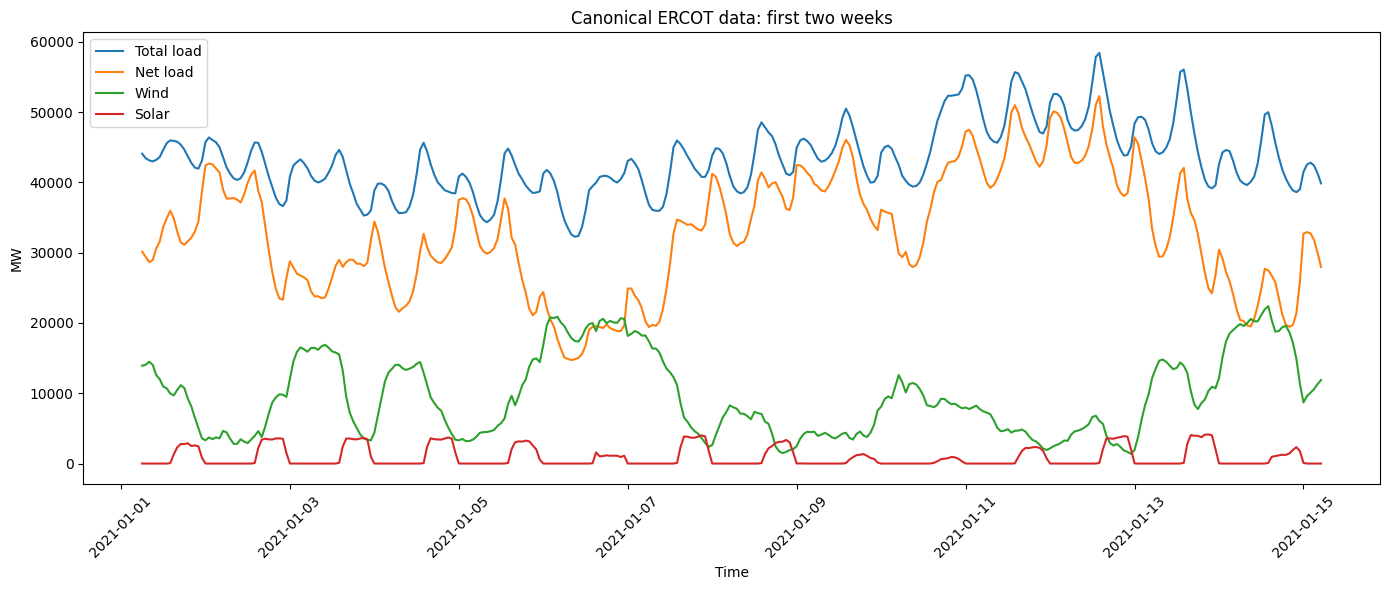

In [7]:
view = data.iloc[:24 * 14]
plt.figure(figsize=(14, 6))
plt.plot(view["time"], view["total_load"], label="Total load")
plt.plot(view["time"], view["net_load"], label="Net load")
plt.plot(view["time"], view["wind_generation"], label="Wind")
plt.plot(view["time"], view["solar_generation"], label="Solar")
plt.xlabel("Time")
plt.ylabel("MW")
plt.title("Canonical ERCOT data: first two weeks")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()
